# Is FP8 rounding behind the random-push escapes? (analysis demo)

**The question.** In iteration 4 of this research run, 40 fixed random directions (seeds 9101–9140) were added to Qwen3-8B's hidden states while it wrote a Python solution. The push acted at blocks 12–23 and at the task-specification tokens. Many pushes changed **which algorithm** the model wrote: for connected components (task T10), DFS or BFS instead of its default union-find. Such a change is called an **escape**. All of these programs came from an FP8 W8A8 inference engine. This artifact asks whether the escapes come from **the model** or from the **FP8 rounding**.

**The design.** The same directions, prompts, sampling slots (common random numbers, CRN) and push size were re-run under four numerics, all built from one bf16 snapshot:

| engine | weights | activations | role |
|---|---|---|---|
| **a** W8A8 | e4m3 | e4m3 (per token) | iteration-4 engine, reproduced byte for byte |
| **b** W8A16 | e4m3 | bf16 | weight rounding only |
| **c** W16A8 | bf16 | e4m3 (per token) | activation rounding only |
| **d** BF16 | bf16 | bf16 | full-precision reference |

**The escape rule** has two stages. Each engine is scored against its own unpushed **twin** (50 samples).
- **Screen.** Take the first 10 pushed samples (templates W1–W5 × slots k 0–1). Their off-default share must exceed the twin's by at least 0.20. Their pass rate on hidden tests must be at least 0.8 × the twin's.
- **Confirmation.** The pooled 30 samples (k 0–5) must keep the +0.20 excess, with a one-sided exact binomial p < 0.05. They must also keep the pass clause.

E = confirmed directions / directions run.

**Full-run result.** E at α = 2:
- T10: a 0.725, c 0.600, d 0.650; b 0.70 at screen level only, because its confirmation was cut short.
- T2: a 0.200, b 0.125, c 0.150, d 0.150.

The pre-registered verdict is **NOT_REPRODUCED_HIGH** on both tasks: bf16 escapes on almost the same directions as FP8. On T10 the discordant directions are 3 : 0, κ = 0.83 and the Spearman correlation is 0.96. The escapes are therefore a property of the model. FP8 adds only a small per-slot boost on T10. CRN-paired, the off-default rate is 0.583 under FP8 against 0.532 under bf16; discordant slots are 30 : 10, exact McNemar p = 0.0022.

**What this notebook runs.** `method.py` chains three stages: GPU generation on Qwen3-8B (a 16 GB GPU with FP8 tensor cores), an LLM-judge labeller and a CPU analysis. Generation cannot run on Colab, so the notebook runs the **CPU analysis** (`analyse` → `rederive` → `figures`) on stored, labelled programs.

`mini_demo_data.json` holds **every CRN slot of 4 directions on T10 at α = 2**: 100 slots, each with the programs of all four engines. No slot of a chosen direction is left out, so each direction's result equals its full-run result.

The code is copied from `src/escape.py`, `src/analysis.py`, `src/rederive.py` and `src/figures6.py`. Every change needed for the notebook is marked `# demo:`.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# The analysis needs only numpy, scipy, matplotlib and pandas, all pre-installed on Colab, so nothing is installed
# there. Locally they are installed at Colab's exact versions.
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# Import blocks of the original modules (method.py, src/c6.py, src/escape.py, src/analysis.py, src/figures6.py),
# merged. Imports of the vendored iteration-4 code (cfg4, screen, regate_rules, ...) are replaced in the cells below.
import json
import math
import os
import subprocess
import sys
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any, Iterable

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# notebook additions: data loading, result tables, the slot-matrix plot
import http.client
import urllib.request

import pandas as pd
from matplotlib.colors import ListedColormap

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-6/experiment-29/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# An older mini_demo_data.json with a different layout can sit at the URL until this version is pushed;
# use the local copy then.
if "twin_reference" not in data.get("metadata", {}) and Path("mini_demo_data.json").exists():
    print("GitHub copy has an older layout, using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
meta = data["metadata"]
print(meta["description"])
print("selection:", json.dumps(meta["selection"], indent=1))
print(len(data["datasets"][0]["examples"]), "examples in dataset", data["datasets"][0]["dataset"])

GitHub copy has an older layout, using local mini_demo_data.json
Curated subset of the FP8 engine-factorial experiment (Qwen3-8B, iteration-4 random plan-site pushes re-run under W8A8 / W8A16 / W16A8 / bf16 numerics) for code_demo.ipynb.
selection: {
 "dataset": "engine_pop",
 "task": "T10",
 "alpha": 2.0,
 "direction_seeds": [
  9101,
  9102,
  9103,
  9127
 ],
 "slots": "every CRN slot of each direction: screen k 0-1 and confirmation k 2-5 x templates W1-W5 (confirmation slots exist only for engines whose screen passed)",
 "n_examples": 100
}
100 examples in dataset engine_pop


## Configuration

The full run analysed two tasks (T10, T2) and all 40 directions. The demo file holds task T10 and four directions; `N_DIRECTIONS` sets how many of them to analyse, in seed order.

The other four values size the resampling statistics: the Tango CI grid, the landing permutation test and the two placebos of the re-derivation. They are set to the artifact's original values, given in each comment; at this data size they cost a few seconds.

In [5]:
# ---- Config ----
# Which part of mini_demo_data.json to analyse. The full run used TASKS = ("T10", "T2") and all 40 direction seeds
# 9101-9140; the demo file holds every CRN slot of 4 T10 directions (9101, 9102, 9103, 9127).
TASKS = ("T10",)          # original: ("T10", "T2")
N_DIRECTIONS = 4          # directions analysed, in seed order (max 4 in the demo file; original: 40)

# Sizes of the resampling statistics: the artifact's original values (a few seconds here)
TANGO_GRID = 8001         # grid points of the paired Tango score CI (original: 8001)
N_PERM_LANDINGS = 5000    # permutations of the landing-composition test (original: 5000)
N_PLACEBO_DRAWS = 10000   # rederive placebo P1 draws: engine labels shuffled within direction (original: 10000)
N_PLACEBO_PERMS = 2000    # rederive placebo P2 draws: direction pairing permuted (original: 2000)

## 1. The pipeline (`method.py`)

`method.py` is the artifact's entry point. `uv run method.py <step>` runs one step; `uv run method.py all` runs every step in order and starts the labeller in the background. Each step is a script under `src/`:

- **setup / gates / commit0**: copy and hash the inputs from earlier iterations, run CPU gates C1–C5, and write the hash-chained pre-registration of the decision rules.
- **q1 / b / q2** (GPU): generate programs with Qwen3-8B. Engines a and b use the FP8 weight set "Q"; engines c and d use the bf16 weight set "B". One 16 GB card holds one weight set at a time.
- **label** (background): label each program with its algorithm and run the hidden tests. Labels come from a runtime classifier and an AST classifier, with LLM judges called when the two disagree.
- **analyse / rederive / figures / outputs** (CPU): the statistics, an independent re-derivation, the figures and the bookkeeping.

The GPU and labeller steps need the model, an FP8-capable GPU and API keys. Their output, one label per program, ships in the demo file, and the notebook runs the three CPU steps on it.

In [6]:
# From method.py: each step is a script under src/ (`uv run method.py <step>`); `method.py all` runs ORDER.
STEPS = {
    "setup": ["src/setup_inputs.py"],
    "gates": ["src/cpu_gates.py"],
    "commit0": ["src/make_commit0.py"],
    "label": ["src/label_worker6.py"],
    "q1": ["src/gpu_q.py", "--phase", "q1"],
    "b": ["src/gpu_b.py"],
    "q2": ["src/gpu_q.py", "--phase", "q2"],
    "analyse": ["src/analysis.py"],
    "rederive": ["src/rederive.py"],
    "figures": ["src/figures6.py"],
    "outputs": ["src/finalize6.py"],
}
ORDER = ["setup", "gates", "commit0", "q1", "b", "q2", "analyse", "rederive", "figures", "outputs"]

# demo: where each step is covered in this notebook
IN_NOTEBOOK = {
    "setup": "not run (copies + sha256-verifies the earlier-artifact inputs)",
    "gates": "not run (CPU gates C1-C5 over iteration-4 files; all passed in the full run)",
    "commit0": "not run (hash-chained pre-registration of the decision rules)",
    "label": "not run (labeller + OpenRouter judges); its labels ship in mini_demo_data.json",
    "q1": "not run (GPU: engine-a REPRO, 400/400 rows byte-identical to iteration 4)",
    "b": "not run (GPU: engines d and c, bf16 weights)",
    "q2": "not run (GPU: engine b, W8A16)",
    "analyse": "RUN in sections 2-7",
    "rederive": "RUN in section 8 (isolated interpreter, as in method.py)",
    "figures": "RUN in sections 9-10",
    "outputs": "not run (bookkeeping, method_out.json)",
}
for s in ["label"] + ORDER:
    print(f"{s:9s} {' '.join(STEPS[s]):28s} {IN_NOTEBOOK[s]}")

label     src/label_worker6.py         not run (labeller + OpenRouter judges); its labels ship in mini_demo_data.json
setup     src/setup_inputs.py          not run (copies + sha256-verifies the earlier-artifact inputs)
gates     src/cpu_gates.py             not run (CPU gates C1-C5 over iteration-4 files; all passed in the full run)
commit0   src/make_commit0.py          not run (hash-chained pre-registration of the decision rules)
q1        src/gpu_q.py --phase q1      not run (GPU: engine-a REPRO, 400/400 rows byte-identical to iteration 4)
b         src/gpu_b.py                 not run (GPU: engines d and c, bf16 weights)
q2        src/gpu_q.py --phase q2      not run (GPU: engine b, W8A16)
analyse   src/analysis.py              RUN in sections 2-7
rederive  src/rederive.py              RUN in section 8 (isolated interpreter, as in method.py)
figures   src/figures6.py              RUN in sections 9-10
outputs   src/finalize6.py             not run (bookkeeping, method_out.json)


## 2. Constants and rows

The constants come from `src/c6.py` and `src/analysis.py`. Each task has a **catalogue** of recognised algorithms and a **default**, the algorithm the unpushed model writes. A program is **off-default** when its label is in the catalogue but is not the default. Two kinds of label get special treatment in the off-default share:
- `other` (an unrecognised algorithm) counts as not off-default;
- `invalid` and `disputed` programs are left out of the denominator.

In [7]:
# From src/c6.py. demo: ROOT is a local working folder, not the artifact folder. As in the full pipeline, the analysis
# writes results/*.json and data/samples.jsonl there, and src/rederive.py reads them back.
ROOT = Path("fp8_escape_demo").resolve()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGS = ROOT / "figures"
for _d in (DATA, RESULTS, FIGS, ROOT / "src"):
    _d.mkdir(parents=True, exist_ok=True)

ENGINES = {"a": "W8A8", "b": "W8A16", "c": "W16A8", "d": "BF16"}
SEEDS_POP = list(range(9101, 9141))
DEFAULTS = {"T10": "union_find", "T2": "dijkstra", "T03": "full_sort"}


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as f:
        for r in rows:
            f.write(json.dumps(r, default=_json_default) + "\n")
        f.flush()
        os.fsync(f.fileno())


def _json_default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
    except ImportError:
        pass
    return str(o)


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


# From src/analysis.py (its TASKS tuple is the config cell's TASKS here)
ENGS = ("a", "b", "c", "d")
PAIRS = [("a", "d"), ("c", "d"), ("b", "d"), ("a", "c"), ("a", "b")]
PRIMARY = [("a", "d"), ("c", "d"), ("b", "d")]

# demo: analysis.catalogue() calls the vendored exp22 `screen.catalogue`, which reads the task specs under vendor/.
# These are its values (the same table src/rederive.py hard-codes).
CATALOGUE = {"T10": ["bfs", "dfs", "union_find", "label_propagation"],
             "T2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]}


def catalogue(task: str) -> set[str]:
    return set(CATALOGUE[task])


print("catalogue / default:", {t: (sorted(catalogue(t)), DEFAULTS[t]) for t in TASKS})

catalogue / default: {'T10': (['bfs', 'dfs', 'label_propagation', 'union_find'], 'union_find')}


### From labelled programs to analysis rows

In the full pipeline, `src/rows6.py` joins each generated program (`data/raw/raw_<engine>.jsonl`) with its label (`data/labels.jsonl`). It also reuses iteration 4's engine-a rows wherever they were reproduced byte for byte.

The demo file stores the joined result: one example per CRN slot, with `predict_<engine>` = `"<algorithm>|<pass or fail>"` for each engine that ran the slot. Confirmation slots (k 2–5) exist only for engines whose screen passed. The cell below turns each (slot, engine) pair into the row dict that `analysis.py` works on.

The escape rule also needs each engine's **twin**: 50 unpushed samples of the same prompts. The twin is a separate dataset (`engine_twins`), so the demo file carries only each engine's twin summary, under `metadata.twin_reference`. On T10, all 50 twin programs of every engine are `union_find` and all pass the tests: share 0, pass rate 1.0.

In [8]:
# demo: replaces rows6.engine_rows / analysis.load_all, which join data/raw/raw_<engine>.jsonl with
# data/labels.jsonl (and reuse iteration 4's byte-identical engine-a rows). One example = one CRN slot.
EXAMPLES = data["datasets"][0]["examples"]
DEMO_SEEDS = sorted({ex["metadata_direction_seed"] for ex in EXAMPLES})[:N_DIRECTIONS]
TWIN_REF = meta["twin_reference"]          # {task: {engine: twin record of escape.share()}}


def rows_from_examples(examples: list[dict[str, Any]], seeds: list[int]) -> dict[str, dict[str, list[dict[str, Any]]]]:
    R: dict[str, dict[str, list[dict[str, Any]]]] = {}
    for ex in examples:
        if ex["metadata_task"] not in TASKS or ex["metadata_direction_seed"] not in seeds:
            continue
        for e in ENGS:
            v = ex.get(f"predict_{e}")
            if v is None:       # this engine did not run the slot
                continue
            label, ok = v.split("|")
            R.setdefault(e, {}).setdefault(ex["metadata_task"], []).append({
                "engine": e, "task": ex["metadata_task"], "arm": ex["metadata_arm"],
                "template": ex["metadata_template"], "sample_id": ex["metadata_k"], "family": ex["metadata_family"],
                "alpha": ex["metadata_alpha"], "direction_seed": ex["metadata_direction_seed"],
                "stage": ex["metadata_phase"], "label": label, "passed": ok == "pass",
                "source": ex["metadata_engine_a_source"] if e == "a" else "this_run"})
    return R


R = rows_from_examples(EXAMPLES, DEMO_SEEDS)
print("directions:", DEMO_SEEDS, "| twin T10:", {e: (TWIN_REF["T10"][e]["share"], TWIN_REF["T10"][e]["pass"]) for e in ENGS})
comp = pd.DataFrame([{"task": t, "direction": s, "engine": e,
                      "rows": sum(1 for r in R[e][t] if r["direction_seed"] == s),
                      "label|tests": dict(Counter(f"{r['label']}|{'pass' if r['passed'] else 'fail'}"
                                                  for r in R[e][t] if r["direction_seed"] == s))}
                     for t in TASKS for s in DEMO_SEEDS for e in ENGS if t in R.get(e, {})])
print(comp.to_string(index=False))
print("\nexample row:", R["a"][TASKS[0]][0])

directions: [9101, 9102, 9103, 9127] | twin T10: {'a': (0.0, 1.0), 'b': (0.0, 1.0), 'c': (0.0, 1.0), 'd': (0.0, 1.0)}
task  direction engine  rows                                            label|tests
 T10       9101      a    10                                {'union_find|pass': 10}
 T10       9101      b    10                                {'union_find|pass': 10}
 T10       9101      c    10                                {'union_find|pass': 10}
 T10       9101      d    10                                {'union_find|pass': 10}
 T10       9102      a    30 {'union_find|pass': 13, 'dfs|pass': 12, 'bfs|pass': 5}
 T10       9102      b    26  {'union_find|pass': 9, 'dfs|pass': 13, 'bfs|pass': 4}
 T10       9102      c    30  {'union_find|pass': 17, 'dfs|pass': 8, 'bfs|pass': 5}
 T10       9102      d    30 {'union_find|pass': 10, 'dfs|pass': 15, 'bfs|pass': 5}
 T10       9103      a    30                {'dfs|pass': 18, 'union_find|pass': 12}
 T10       9103      b    26              

## 3. The two-stage escape rule (`src/escape.py`)

This is iteration 4's (exp22's) rule, re-implemented. In the full run, CPU gate C3 checked that it reproduces exp22's `escape.json` exactly. The module has three parts:
- `share()` gives the off-default share and pass rate of a set of rows.
- `cell_eval()` scores one direction × α cell against the twin. It applies the screen to k 0–1, then the confirmation to the pooled k 0–5. A cell can be confirmed only if it passed the screen and has rows beyond it.
- `escape_table()` runs every direction of one engine and task, and returns E per α.

The binomial null is p0 = (k_twin + 0.5) / (n_twin + 1), the twin's off-default rate with a half-count added. For T10's twin, p0 = 0.5 / 51 ≈ 0.01.

The cell writes the module to `fp8_escape_demo/src/escape.py`. The analysis then imports it the way `analysis.py` does (`from escape import escape_table, share`), which keeps the module's own names, such as the threshold functions `ESC()` and `PASSF()`, separate from the notebook's.

**demo change:** `escape_table` takes an optional `twin` record. The demo rows hold no twin arm, so the stored twin summary is passed in. Without `twin`, the original computation runs.

In [9]:
%%writefile fp8_escape_demo/src/escape.py
#!/usr/bin/env python3
"""exp22's two-stage escape rule, re-implemented from the text in predictions/c2_commit.json (committed here before
any decisive sample; gate C3 checks it reproduces exp22 results/escape.json exactly from exp22's own labels).

Rule text (c2_commit.json 'escape_confirmation'):
  Screen pass at N = 10: excess >= 0.20 over the twin (N = 50, k 0-9) and pass >= 0.8 x twin.
  CONFIRMED if the pooled 30 (k 0-5) keeps excess >= 0.20 with one-sided exact binomial p < 0.05 against
  p0 = (k_twin + 0.5) / (n_twin + 1), and pass >= 0.8 x twin. E_t(alpha) = confirmed / run.
Shares (exp22 analysis/common.py docstring): off-default share = #(catalogue label != default) / #valid, with
'invalid' and 'disputed' excluded from the denominator and 'other' counted as NOT off-default. Pass = passed the
hidden tests over all attempts. Screen rows = k in {0, 1}; pooled rows = k in 0..5; a cell is 'confirmed' only if it
passed the screen and has rows beyond the screen (topped up).
"""

from __future__ import annotations

from collections import defaultdict
from typing import Any, Iterable

from scipy import stats

EXCLUDE = ("invalid", "disputed")
TOL = 1e-12


def share(rows: Iterable[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    rows = list(rows)
    valid = [r for r in rows if r["label"] not in EXCLUDE]
    off = sum(1 for r in valid if r["label"] in cat and r["label"] != default)
    n = len(valid)
    npass = sum(1 for r in rows if r["passed"])
    return {"n": len(rows), "n_valid": n, "k_off": off, "share": off / n if n else float("nan"),
            "pass": npass / len(rows) if rows else float("nan"), "k_pass": npass,
            "n_other": sum(1 for r in rows if r["label"] == "other"),
            "n_invalid": sum(1 for r in rows if r["label"] == "invalid"),
            "n_disputed": sum(1 for r in rows if r["label"] == "disputed")}


def binom_greater(k: int, n: int, p0: float) -> float:
    return float(stats.binomtest(k, n, p0, alternative="greater").pvalue) if n > 0 else 1.0


def twin_rows(rows: list[dict[str, Any]], kmax: int = 10) -> list[dict[str, Any]]:
    return [r for r in rows if r["arm"] == "TWIN" and int(r["sample_id"]) < kmax]


def cell_eval(cell_rows: list[dict[str, Any]], tw: dict[str, Any], cat: set[str], default: str) -> dict[str, Any]:
    p0 = (tw["k_off"] + 0.5) / (tw["n_valid"] + 1)
    first = [r for r in cell_rows if int(r["sample_id"]) in (0, 1)]
    pooled = [r for r in cell_rows if 0 <= int(r["sample_id"]) <= 5]
    f, pl = share(first, cat, default), share(pooled, cat, default)
    screen = bool(f["n_valid"] > 0 and f["share"] - tw["share"] >= ESC() - TOL
                  and f["pass"] >= PASSF() * tw["pass"] - TOL)
    topped = pl["n"] > f["n"]
    conf, pbin = False, None
    if screen and topped:
        pbin = binom_greater(pl["k_off"], pl["n_valid"], p0)
        conf = bool(pl["share"] - tw["share"] >= ESC() - TOL and pbin < 0.05
                    and pl["pass"] >= PASSF() * tw["pass"] - TOL)
    return {"first10": f, "pooled": pl, "screen_pass": screen, "topped_up": topped, "binom_p": pbin,
            "confirmed": conf, "excess_first10": f["share"] - tw["share"] if f["n_valid"] else None,
            "excess_pooled": pl["share"] - tw["share"] if pl["n_valid"] else None, "p0": p0}


def ESC() -> float:
    return 0.20


def PASSF() -> float:
    return 0.8


def escape_table(rows: list[dict[str, Any]], seeds: list[int], cat: set[str], default: str,
                 alphas: tuple[float, ...] = (1.0, 2.0), family: str = "POP",
                 twin: dict[str, Any] | None = None) -> dict[str, Any]:
    """rows: joined label rows of ONE engine and task (TWIN + POP arms). Returns twin stats, per-direction cells and
    E_t per alpha (confirmed / n_run, n_run = directions with any screen row at that alpha)."""
    tw = share(twin_rows(rows), cat, default) if twin is None else twin   # demo: optional stored twin record
    pop = defaultdict(list)
    for r in rows:
        if r.get("family") == family and r.get("direction_seed") is not None:
            pop[(int(r["direction_seed"]), float(r["alpha"]))].append(r)
    cells: dict[str, dict[str, Any]] = {}
    E: dict[str, dict[str, Any]] = {}
    for a in alphas:
        n_run = n_screen = n_conf = 0
        for s in seeds:
            rr = pop.get((s, float(a)), [])
            if not any(int(r["sample_id"]) in (0, 1) for r in rr):
                continue
            n_run += 1
            c = cell_eval(rr, tw, cat, default)
            cells[f"{s}|{a}"] = c
            n_screen += c["screen_pass"]
            n_conf += c["confirmed"]
        E[str(a)] = {"n_run": n_run, "n_screen_pass": n_screen, "n_confirmed": n_conf,
                     "E_t": n_conf / n_run if n_run else float("nan"),
                     "E_screen": n_screen / n_run if n_run else float("nan")}
    return {"twin": tw, "cells": cells, "E_t": E}


def needs_confirmation(rows: list[dict[str, Any]], seeds: list[int], cat: set[str], default: str,
                       alpha: float) -> list[int]:
    """Directions whose screen passes at `alpha` and that are not yet topped up."""
    t = escape_table(rows, seeds, cat, default, alphas=(alpha,))
    out = []
    for s in seeds:
        c = t["cells"].get(f"{s}|{alpha}")
        if c and c["screen_pass"] and not c["topped_up"]:
            out.append(s)
    return out

Writing fp8_escape_demo/src/escape.py


## 4. Statistics helpers (`src/analysis.py`)

The cell first imports the escape module written above, as `analysis.py` does. It then defines the helpers:
- `mcnemar_exact`: exact McNemar test on paired 0/1 indicators. It is applied to directions (escape under engine x vs y) and to CRN slots (off-default under x vs y).
- `tango_ci`: Tango's score CI for a paired difference, used with a TOST equivalence check at margin 0.1.
- `holm`: Holm's step-down adjustment over the primary family {a-d, c-d, b-d}.
- `kappa`, `spearman`: per-direction agreement between two engines.
- `perm_chi2`: Monte-Carlo permutation test of independence for a table. It asks whether engines land on the same algorithms in the same proportions.

**demo change:** the Tango grid size comes from the config cell.

In [10]:
# As analysis.py: put src/ on sys.path, then `from escape import escape_table, share`
import importlib

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import escape  # noqa: E402
importlib.reload(escape)   # demo: re-reads the module file when the cells are re-run
from escape import escape_table, share  # noqa: E402


# ------------------------------------------------------------------------------------------------ statistics
def mcnemar_exact(x: list[int], y: list[int]) -> dict[str, Any]:
    n10 = sum(1 for a, b in zip(x, y) if a and not b)
    n01 = sum(1 for a, b in zip(x, y) if b and not a)
    m = n10 + n01
    p2 = 1.0 if m == 0 else min(1.0, 2 * stats.binom.cdf(min(n10, n01), m, 0.5))
    p_gt = 1.0 if m == 0 else float(stats.binom.sf(n10 - 1, m, 0.5))   # H1: P(x) > P(y)
    return {"n10": n10, "n01": n01, "p_two_sided": float(p2), "p_one_sided_x_gt_y": p_gt}


def tango_ci(n10: int, n01: int, n: int, level: float = 0.90) -> tuple[float, float]:
    """Tango (1998) score CI for the paired difference p_x - p_y = (n10 - n01) / n."""
    if n == 0:
        return (float("nan"), float("nan"))
    z = stats.norm.ppf(0.5 + level / 2)
    grid = np.linspace(-1, 1, TANGO_GRID)   # demo: grid size from the config cell (original 8001)
    ok = []
    for d in grid:
        A = 2 * n
        B = -n10 - n01 + (2 * n - n10 + n01) * d
        C = -n01 * d * (1 - d)
        disc = max(B * B - 4 * A * C, 0.0)
        q21 = (math.sqrt(disc) - B) / (2 * A)
        var = n * (2 * q21 + d * (1 - d))
        if var <= 0:
            stat = 0.0 if (n10 - n01 - n * d) == 0 else float("inf")
        else:
            stat = (n10 - n01 - n * d) / math.sqrt(var)
        if abs(stat) <= z:
            ok.append(d)
    return (float(min(ok)), float(max(ok))) if ok else (float("nan"), float("nan"))


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


def kappa(x: list[int], y: list[int]) -> float:
    n = len(x)
    if n == 0:
        return float("nan")
    po = sum(1 for a, b in zip(x, y) if a == b) / n
    px, py = sum(x) / n, sum(y) / n
    pe = px * py + (1 - px) * (1 - py)
    return float("nan") if pe == 1 else (po - pe) / (1 - pe)


def spearman(x: list[float], y: list[float]) -> float | None:
    xx = np.array(x, float)
    yy = np.array(y, float)
    ok = ~(np.isnan(xx) | np.isnan(yy))
    if ok.sum() < 3 or np.std(xx[ok]) == 0 or np.std(yy[ok]) == 0:
        return None
    return float(stats.spearmanr(xx[ok], yy[ok]).statistic)


def perm_chi2(table: np.ndarray, n_perm: int = 10000, seed: int = 0) -> dict[str, Any]:
    """Monte-Carlo permutation test of independence for an r x c table (Fisher-Freeman-Halton surrogate)."""
    table = np.asarray(table, int)
    table = table[:, table.sum(0) > 0]
    if table.shape[1] < 2 or (table.sum(1) == 0).any():
        return {"chi2": None, "p_perm": None, "table": table.tolist()}
    rows = np.repeat(np.arange(table.shape[0]), table.sum(1))
    cols = np.concatenate([np.repeat(np.arange(table.shape[1]), table[i]) for i in range(table.shape[0])])

    def chi2(r, c):
        t = np.zeros(table.shape)
        np.add.at(t, (r, c), 1)
        e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
        return float(((t - e) ** 2 / np.where(e > 0, e, 1)).sum())
    obs = chi2(rows, cols)
    rng = np.random.default_rng(seed)
    ge = sum(chi2(rows, rng.permutation(cols)) >= obs - 1e-9 for _ in range(n_perm))
    return {"chi2": obs, "p_perm": (ge + 1) / (n_perm + 1), "n_perm": n_perm, "table": table.tolist()}


print("exact McNemar of the full run's T10 a-d screen slots (30 vs 10 discordant):",
      mcnemar_exact([1] * 30 + [0] * 10, [0] * 30 + [1] * 10))

exact McNemar of the full run's T10 a-d screen slots (30 vs 10 discordant): {'n10': 30, 'n01': 10, 'p_two_sided': 0.0022214337732293643, 'p_one_sided_x_gt_y': 0.0011107168866146822}


## 5. Escape fraction per engine

`escape_by_engine` runs the rule for every engine and task. For each α it records:
- E and the screen-level E (screen passes / directions), each with a Wilson 95% interval;
- each direction's first-10 share and pass rate;
- a `confirmation_complete` flag.

An engine whose screen passers were not all topped up to the pooled 30 rows gets only a screen-level E. In the full run, this happened to engine b on T10, which ran out of time. The demo directions keep b's real row counts (26 or 22 pooled rows), so the flag reproduces here.

In [11]:
# ------------------------------------------------------------------------------------------------ escape
def escape_by_engine(R) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for e in ENGS:
        for t in TASKS:
            rr = R.get(e, {}).get(t)
            if not rr:
                continue
            alphas = tuple(sorted({float(r["alpha"]) for r in rr if r["family"] == "POP"
                                   and r.get("direction_seed") in SEEDS_POP} & {1.0, 2.0}))
            # demo: each engine's own twin record from the stored twin reference (the demo rows hold no twin arm)
            tab = escape_table(rr, SEEDS_POP, catalogue(t), DEFAULTS[t], alphas=alphas, twin=TWIN_REF[t][e])
            pc = escape_table(rr, [9004], catalogue(t), DEFAULTS[t], alphas=(1.0,),
                              twin=TWIN_REF[t][e]) if t == "T2" else None
            per_alpha = {}
            for a in alphas:
                E = tab["E_t"][str(a)]
                cells = {s: tab["cells"].get(f"{s}|{a}") for s in SEEDS_POP}
                n_pass_untopped = sum(1 for c in cells.values() if c and c["screen_pass"] and c["pooled"]["n"] < 30)
                tw = tab["twin"]
                n_excess_only = sum(1 for c in cells.values() if c and not c["screen_pass"] and c["first10"]["n_valid"]
                                    and c["first10"]["share"] - tw["share"] >= 0.2 - 1e-12)
                per_alpha[str(a)] = {
                    **E, "n_excess_met_but_pass_clause_failed": n_excess_only,
                    "mean_share10": float(np.nanmean([c["first10"]["share"] for c in cells.values() if c])),
                    "mean_pass10": float(np.nanmean([c["first10"]["pass"] for c in cells.values() if c])),
                    "E_wilson": wilson(E["n_confirmed"], E["n_run"]) if E["n_run"] else None,
                    "E_screen_wilson": wilson(E["n_screen_pass"], E["n_run"]) if E["n_run"] else None,
                    "confirmation_complete": n_pass_untopped == 0, "n_screen_pass_not_confirmed_tested": n_pass_untopped,
                    "per_direction": {str(s): None if c is None else {
                        "share10": c["first10"]["share"], "pass10": c["first10"]["pass"], "screen": c["screen_pass"],
                        "confirmed": c["confirmed"], "share30": c["pooled"]["share"] if c["topped_up"] else None,
                        "n_invalid10": c["first10"]["n_invalid"], "binom_p": c["binom_p"]} for s, c in cells.items()}}
            out.setdefault(e, {})[t] = {"twin": tab["twin"], "alpha": per_alpha,
                                        "posctrl_9004_a1": None if pc is None else pc["cells"].get("9004|1.0")}
    return out


ESC = escape_by_engine(R)

summary = pd.DataFrame([{"task": t, "engine": f"{e} {ENGINES[e]}",
                         "twin off-default": f"{ESC[e][t]['twin']['k_off']}/{ESC[e][t]['twin']['n_valid']}",
                         "twin pass": ESC[e][t]["twin"]["pass"], "directions": v["n_run"],
                         "screen passes": v["n_screen_pass"], "confirmed": v["n_confirmed"],
                         "E": round(v["E_t"], 3) if v["confirmation_complete"] else "incomplete",
                         "E screen-level": round(v["E_screen"], 3),
                         "pass clause failed": v["n_excess_met_but_pass_clause_failed"]}
                        for e in ESC for t in ESC[e] for v in [ESC[e][t]["alpha"]["2.0"]]])
print(summary.to_string(index=False))
print()
per_dir = pd.DataFrame([{"task": t, "direction": int(s), "engine": e, "share10": c["share10"], "pass10": c["pass10"],
                         "screen": c["screen"], "share30": c["share30"], "binom_p": c["binom_p"],
                         "confirmed": c["confirmed"]}
                        for e in ESC for t in ESC[e] for s, c in ESC[e][t]["alpha"]["2.0"]["per_direction"].items() if c])
print(per_dir.sort_values(["task", "direction", "engine"]).to_string(index=False))

task  engine twin off-default  twin pass  directions  screen passes  confirmed          E  E screen-level  pass clause failed
 T10  a W8A8             0/50        1.0           4              3          3       0.75            0.75                   0
 T10 b W8A16             0/50        1.0           4              3          3 incomplete            0.75                   0
 T10 c W16A8             0/50        1.0           4              2          2        0.5            0.50                   1
 T10  d BF16             0/50        1.0           4              3          3       0.75            0.75                   0

task  direction engine  share10  pass10  screen  share30      binom_p  confirmed
 T10       9101      a      0.0     1.0   False      NaN          NaN      False
 T10       9101      b      0.0     1.0   False      NaN          NaN      False
 T10       9101      c      0.0     1.0   False      NaN          NaN      False
 T10       9101      d      0.0     1.0   Fal

### Check against the full run

Every example also stores the full run's outcome for its direction under each engine, as `metadata_escape_<engine>`: screen pass, confirmed, first-10 share. All slots of each demo direction are present, so the values recomputed above must equal these exactly.

In [12]:
# The full run's per-direction outcome is stored on every example as metadata_escape_<engine>
stored = {(e, ex["metadata_task"], ex["metadata_direction_seed"]): ex[f"metadata_escape_{e}"]
          for ex in EXAMPLES for e in ENGS
          if ex.get(f"metadata_escape_{e}") is not None and ex["metadata_task"] in TASKS
          and ex["metadata_direction_seed"] in DEMO_SEEDS}
check = []
for (e, t, s), m in sorted(stored.items()):
    c = ESC[e][t]["alpha"]["2.0"]["per_direction"][str(s)]
    check.append({"task": t, "direction": s, "engine": e,
                  "screen (full run / here)": f"{m['screen']} / {c['screen']}",
                  "confirmed (full run / here)": f"{m['confirmed']} / {c['confirmed']}",
                  "share10 (full run / here)": f"{m['share10']:.1f} / {c['share10']:.1f}",
                  "match": m["screen"] == c["screen"] and m["confirmed"] == c["confirmed"]
                           and abs(m["share10"] - c["share10"]) < 1e-9})
check = pd.DataFrame(check)
print(check.to_string(index=False))
print(f"\n{int(check['match'].sum())}/{len(check)} engine x direction outcomes equal the full run's")

task  direction engine screen (full run / here) confirmed (full run / here) share10 (full run / here)  match
 T10       9101      a            False / False               False / False                 0.0 / 0.0   True
 T10       9102      a              True / True                 True / True                 0.6 / 0.6   True
 T10       9103      a              True / True                 True / True                 0.9 / 0.9   True
 T10       9127      a              True / True                 True / True                 1.0 / 1.0   True
 T10       9101      b            False / False               False / False                 0.0 / 0.0   True
 T10       9102      b              True / True                 True / True                 0.6 / 0.6   True
 T10       9103      b              True / True                 True / True                 0.8 / 0.8   True
 T10       9127      b              True / True                 True / True                 1.0 / 1.0   True
 T10       9101    

## 6. Engine contrasts

### 6a. Direction-paired contrasts

Each direction gives one escape indicator per engine. `pairs_table` compares two engines over the same directions using:
- an exact McNemar test on the discordant directions;
- a 90% Tango CI, with TOST equivalence at ±0.1;
- Cohen's κ;
- the Spearman correlation of the first-10 shares.

Each contrast is computed at two levels. The confirmed level is skipped when an engine's confirmation is incomplete; the screen level is always computed. Holm's adjustment runs over the primary pairs a-d, c-d and b-d.

In the full run on T10, a-d has 3 : 0 discordant directions (p = 0.25), κ = 0.83 and Spearman 0.96. With four directions, the demo shows how the contrasts are computed, not their power.

In [13]:
def pairs_table(ESC) -> dict[str, Any]:
    out: dict[str, Any] = {}
    raw_p = {}
    for t in TASKS:
        for (x, y) in PAIRS:
            if x not in ESC or y not in ESC or t not in ESC[x] or t not in ESC[y]:
                continue
            px = ESC[x][t]["alpha"]["2.0"]["per_direction"]
            py = ESC[y][t]["alpha"]["2.0"]["per_direction"]
            common = [s for s in px if px[s] is not None and py.get(s) is not None]
            complete = (ESC[x][t]["alpha"]["2.0"]["confirmation_complete"]
                        and ESC[y][t]["alpha"]["2.0"]["confirmation_complete"])
            for level in ("confirmed", "screen"):
                if level == "confirmed" and not complete:
                    out[f"{t}|{x}-{y}|{level}"] = {"status": "confirmation incomplete for an engine; see screen level"}
                    continue
                xs = [int(px[s][level]) for s in common]
                ys = [int(py[s][level]) for s in common]
                mc = mcnemar_exact(xs, ys)
                lo, hi = tango_ci(mc["n10"], mc["n01"], len(common))
                diff = (sum(xs) - sum(ys)) / len(common) if common else float("nan")
                rec = {"n_dirs": len(common), "E_x": sum(xs) / len(common) if common else None,
                       "E_y": sum(ys) / len(common) if common else None, "diff": diff, **mc,
                       "tango90": [lo, hi], "tost_margin_0.1_equivalent": bool(lo > -0.1 and hi < 0.1),
                       "kappa": kappa(xs, ys),
                       "spearman_share10": spearman([px[s]["share10"] for s in common],
                                                    [py[s]["share10"] for s in common])}
                out[f"{t}|{x}-{y}|{level}"] = rec
                if level == "confirmed" and (x, y) in PRIMARY:
                    raw_p[f"{t}|{x}-{y}"] = mc["p_two_sided"]
    hp = holm(raw_p) if raw_p else {}
    for k, v in hp.items():
        out[f"{k}|confirmed"]["p_holm"] = v
    out["holm_family"] = sorted(raw_p)
    return out


PAIR = pairs_table(ESC)
cols = ("n_dirs", "E_x", "E_y", "n10", "n01", "p_two_sided", "p_holm", "tango90", "tost_margin_0.1_equivalent",
        "kappa", "spearman_share10")
tab = pd.DataFrame([{"contrast": k, **{c: v.get(c) for c in cols}} for k, v in PAIR.items()
                    if k != "holm_family" and "status" not in v]).round(3)
tab["tango90"] = tab["tango90"].map(lambda ci: [round(x, 3) for x in ci])
print(tab.to_string(index=False))
for k, v in PAIR.items():
    if k != "holm_family" and "status" in v:
        print(f"{k}: {v['status']}")
print("Holm family:", PAIR["holm_family"])

         contrast  n_dirs  E_x  E_y  n10  n01  p_two_sided  p_holm         tango90  tost_margin_0.1_equivalent  kappa  spearman_share10
T10|a-d|confirmed       4 0.75 0.75    0    0          1.0     1.0 [-0.403, 0.403]                       False    1.0               1.0
   T10|a-d|screen       4 0.75 0.75    0    0          1.0     NaN [-0.403, 0.403]                       False    1.0               1.0
T10|c-d|confirmed       4 0.50 0.75    0    1          1.0     1.0 [-0.644, 0.254]                       False    0.5               1.0
   T10|c-d|screen       4 0.50 0.75    0    1          1.0     NaN [-0.644, 0.254]                       False    0.5               1.0
   T10|b-d|screen       4 0.75 0.75    0    0          1.0     NaN [-0.403, 0.403]                       False    1.0               1.0
T10|a-c|confirmed       4 0.75 0.50    1    0          1.0     NaN [-0.254, 0.644]                       False    0.5               1.0
   T10|a-c|screen       4 0.75 0.50    1    0   


T10|b-d|confirmed: confirmation incomplete for an engine; see screen level
T10|a-b|confirmed: confirmation incomplete for an engine; see screen level
Holm family: ['T10|a-d', 'T10|c-d']


### 6b. CRN-paired slot flips

Each pushed sample can be paired with **the same CRN slot** in another engine: same direction, template, k and sampling uniforms, so only the numerics differ. `slot_flips` compares the per-slot off-default indicator between engines with an exact McNemar test, in two ways:
- **Primary:** the screen slots (k 0–1), which every engine ran for every direction.
- **Secondary:** all common slots. This adds the confirmation slots, which exist only after a screen pass, so it carries a selection effect.

In the full run, a vs d on T10's 400 screen slots gives off-default 0.583 vs 0.532, with discordant slots 30 : 10 (p = 0.0022). This is the small FP8 boost.

In [14]:
def slot_flips(R) -> dict[str, Any]:
    """CRN-paired per-slot comparison of POP alpha-2 rows (same direction, template, k and uniforms in both engines):
    off-default indicator per slot, exact McNemar on the discordant slots, and label identity of the paired slots."""
    out: dict[str, Any] = {}
    for t in TASKS:
        cat, dft = catalogue(t), DEFAULTS[t]
        ind = {}
        labs = {}
        for e in ENGS:
            rr = [r for r in R.get(e, {}).get(t, []) if r["family"] == "POP" and r.get("alpha") == 2.0
                  and r.get("direction_seed") in SEEDS_POP and r["label"] not in ("invalid", "disputed")]
            ind[e] = {(r["direction_seed"], r["template"], int(r["sample_id"])): int(r["label"] in cat and r["label"] != dft)
                      for r in rr}
            labs[e] = {(r["direction_seed"], r["template"], int(r["sample_id"])): r["label"] for r in rr}
        for (x, y) in PAIRS:
            if not ind.get(x) or not ind.get(y):
                continue
            # primary: the screen slots (k 0-1 of all 40 directions; run in every engine, no selection);
            # secondary: every common slot (adds confirmation slots, which exist only for screen-passing cells)
            for tag, keep in (("", lambda k: k[2] in (0, 1)), ("|all_common_slots", lambda k: True)):
                common = sorted(k for k in set(ind[x]) & set(ind[y]) if keep(k))
                mc = mcnemar_exact([ind[x][k] for k in common], [ind[y][k] for k in common])
                out[f"{t}|{x}-{y}{tag}"] = {
                    "n_slots": len(common), **mc,
                    "same_label_frac": float(np.mean([labs[x][k] == labs[y][k] for k in common])) if common else None,
                    "offdefault_x": float(np.mean([ind[x][k] for k in common])) if common else None,
                    "offdefault_y": float(np.mean([ind[y][k] for k in common])) if common else None}
    return out


SF = slot_flips(R)
print("demo subset:")
print(pd.DataFrame([{"contrast": k, **v} for k, v in SF.items()]).round(4).to_string(index=False))
fs = meta["full_run"]["slot_flips"]
print("\nfull run, T10 screen slots (stored):")
print(pd.DataFrame([{"contrast": k, **{c: fs[k][c] for c in ("n_slots", "n10", "n01", "p_two_sided", "offdefault_x",
                                                           "offdefault_y", "same_label_frac")}}
                    for k in fs if k.startswith("T10") and "all_common" not in k]).round(4).to_string(index=False))

demo subset:
                contrast  n_slots  n10  n01  p_two_sided  p_one_sided_x_gt_y  same_label_frac  offdefault_x  offdefault_y
                 T10|a-d       40    2    0       0.5000              0.2500           0.9000        0.6250        0.5750
T10|a-d|all_common_slots      100    4    3       1.0000              0.5000           0.8800        0.6500        0.6400
                 T10|c-d       40    1    2       1.0000              0.8750           0.8750        0.5500        0.5750
T10|c-d|all_common_slots       80    2    8       0.1094              0.9893           0.8375        0.4750        0.5500
                 T10|b-d       40    1    0       1.0000              0.5000           0.9750        0.6000        0.5750
T10|b-d|all_common_slots       84    4    2       0.6875              0.3438           0.8929        0.6548        0.6310
                 T10|a-c       40    3    0       0.2500              0.1250           0.9000        0.6250        0.5500
T10|a-c|all

## 7. Verdict and landings

### 7a. Verdict (COMMIT #0 table)

The decision table was pre-registered in COMMIT #0, before any decisive sample. It compares the E's at α 2 and returns the first rule that holds:
1. `ACTIVATION_ROUNDING`: E(c) − E(d) ≥ 0.2, |E(a) − E(c)| ≤ 0.1 and |E(b) − E(d)| ≤ 0.1.
2. `WEIGHT`: E(b) − E(d) ≥ 0.2.
3. `INTERACTION`: E(a) − E(d) ≥ 0.2, while E(b) − E(d) < 0.1 and E(c) − E(d) < 0.1.
4. `NOT_REPRODUCED_LOW`: E(a) − E(d) < 0.1 and E(a) < iteration 4's E(a) − 0.15, so the FP8 engine itself no longer escapes as before.
5. `NOT_REPRODUCED_HIGH`: E(a) − E(d) < 0.1 and E(d) ≥ iteration 4's E(a) − 0.15, so bf16 escapes as well.
6. Otherwise `MIXED`.

The literal reading uses confirmed E's and treats an incomplete engine as missing. A screen-level reading is reported beside it.

Iteration 4's relabelled E(a) is a constant from the full run (T10: 0.725). On four directions, the verdict therefore only illustrates the rule. The demo directions do have a typical mix: 3 escapes of 4 under a and d, 2 under c.

In [15]:
def verdicts(ESC, PAIR, E4: dict[str, Any]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for t in TASKS:
        def E(e, level="E_t"):
            try:
                v = ESC[e][t]["alpha"]["2.0"]
            except KeyError:
                return None
            if level == "E_t" and not v["confirmation_complete"]:
                return None
            return v[level]
        Ea, Eb, Ec, Ed = (E(e) for e in ENGS)
        Ea_s, Eb_s, Ec_s, Ed_s = (E(e, "E_screen") for e in ENGS)
        e4 = E4[t]["2.0"]

        def rule(Ea, Eb, Ec, Ed, feas: bool = False):
            if None in (Ea, Ec, Ed):
                return "UNDECIDABLE (missing engine)", {}
            c1 = (Ec - Ed >= 0.2 - 1e-12) if not feas else (
                Ec - Ed >= (2 / 3) * (Ea - Ed) - 1e-12 and
                PAIR.get(f"{t}|c-d|confirmed", {}).get("p_one_sided_x_gt_y", 1) < 0.05)
            clauses = {"c-d": c1, "|a-c|<=0.1": abs(Ea - Ec) <= 0.1 + 1e-12,
                       "|b-d|<=0.1": None if Eb is None else abs(Eb - Ed) <= 0.1 + 1e-12}
            if clauses["c-d"] and clauses["|a-c|<=0.1"] and clauses["|b-d|<=0.1"]:
                return "ACTIVATION_ROUNDING", clauses
            if Eb is not None and Eb - Ed >= 0.2 - 1e-12:
                return "WEIGHT", clauses
            if Eb is not None and Ea - Ed >= 0.2 - 1e-12 and Eb - Ed < 0.1 and Ec - Ed < 0.1:
                return "INTERACTION", clauses
            if Ea - Ed < 0.1 and Ea < e4 - 0.15:
                return "NOT_REPRODUCED_LOW", clauses
            if Ea - Ed < 0.1 and Ed >= e4 - 0.15:
                return "NOT_REPRODUCED_HIGH", clauses
            if Eb is None:
                return "MIXED_OR_UNDECIDABLE (b missing)", clauses
            return "MIXED", clauses
        lit, cl = rule(Ea, Eb, Ec, Ed)
        scr, cls = rule(Ea_s, Eb_s, Ec_s, Ed_s)
        rec = {"E_alpha2": {"a": Ea, "b": Eb, "c": Ec, "d": Ed}, "E_screen_alpha2": {"a": Ea_s, "b": Eb_s, "c": Ec_s,
                                                                                    "d": Ed_s},
               "E_iter4_relabelled_a": e4, "literal_verdict": lit, "literal_clauses": cl,
               "screen_level_verdict": scr, "screen_level_clauses": cls}
        if min(E4[t]["1.0"], E4[t]["2.0"]) < 0.3:
            fv, fcl = rule(Ea, Eb, Ec, Ed, feas=True)
            rec["feasibility_reading"] = {"verdict": fv, "clauses": fcl,
                                          "rule": "E(c)-E(d) >= (2/3)(E(a)-E(d)) and one-sided exact McNemar c>d p<0.05"}
        out[t] = rec
    lits = [out[t]["literal_verdict"] for t in TASKS]
    out["claim"] = {"literal": lits[0] if len(set(lits)) == 1 else "TASKS_DISAGREE: " + " / ".join(lits),
                    "activation_rounding_claim_both_tasks": all(v == "ACTIVATION_ROUNDING" for v in lits)}
    return out


E4 = meta["E_iter4_relabelled_a"]     # iteration 4's E(a) under the current labeller (results/cpu_gates.json, gate C4)
V = verdicts(ESC, PAIR, E4)
for t in TASKS:
    fv = meta["full_run"]["verdict"][t]
    print(f"{t} literal verdict (demo subset): {V[t]['literal_verdict']}")
    print(f"   E(a, b, c, d) = {V[t]['E_alpha2']}   clauses {V[t]['literal_clauses']}")
    print(f"   screen level: {V[t]['screen_level_verdict']} with E_screen = {V[t]['E_screen_alpha2']}")
    print(f"   iteration-4 E(a) = {V[t]['E_iter4_relabelled_a']}, so NOT_REPRODUCED_HIGH needs E(a) - E(d) < 0.1 "
          f"and E(d) >= {V[t]['E_iter4_relabelled_a'] - 0.15:.3f}")
    print(f"   full run (stored): {fv['literal_verdict']} with E = {fv['E_alpha2']}")
print("claim:", V["claim"])

T10 literal verdict (demo subset): NOT_REPRODUCED_HIGH
   E(a, b, c, d) = {'a': 0.75, 'b': None, 'c': 0.5, 'd': 0.75}   clauses {'c-d': False, '|a-c|<=0.1': False, '|b-d|<=0.1': None}
   screen level: NOT_REPRODUCED_HIGH with E_screen = {'a': 0.75, 'b': 0.75, 'c': 0.5, 'd': 0.75}
   iteration-4 E(a) = 0.725, so NOT_REPRODUCED_HIGH needs E(a) - E(d) < 0.1 and E(d) >= 0.575
   full run (stored): NOT_REPRODUCED_HIGH with E = {'a': 0.725, 'b': None, 'c': 0.6, 'd': 0.65}
claim: {'literal': 'NOT_REPRODUCED_HIGH', 'activation_rounding_claim_both_tasks': False}


### 7b. Landings

When a push moves the model off its default, where does it land? `landings` counts each engine's correct off-default programs (label ≠ default, tests passed). A permutation χ² test then asks whether engines a, c and d share one composition. In the full run they do: T10 lands on DFS, then BFS, in every engine (p = 0.22).

**demo change:** the permutation count comes from the config cell.

In [16]:
def landings(R) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for t in TASKS:
        cat, dft = catalogue(t), DEFAULTS[t]
        comp = {}
        for e in ENGS:
            rr = [r for r in R.get(e, {}).get(t, []) if r["family"] == "POP" and r.get("alpha") == 2.0
                  and r["passed"] and r["label"] not in ("invalid", "disputed") and r["label"] != dft]
            comp[e] = dict(Counter(r["label"] for r in rr))
        labs = sorted({l for e in comp for l in comp[e]})
        sub = [e for e in ("a", "c", "d") if comp.get(e)]
        tab = np.array([[comp[e].get(l, 0) for l in labs] for e in sub]) if sub else np.zeros((0, 0))
        out[t] = {"composition_correct_offdefault": comp,
                  "top1": {e: (max(comp[e], key=comp[e].get) if comp[e] else None) for e in comp},
                  # demo: permutation count from the config cell (original 5000)
                  "in_catalogue": sorted(cat), "ffh_perm_a_c_d": perm_chi2(tab, N_PERM_LANDINGS) if len(sub) >= 2 else None,
                  "engines_in_test": sub, "labels": labs}
    return out


L = landings(R)
for t in L:
    fp = L[t]["ffh_perm_a_c_d"] or {}
    fl = meta["full_run"]["landings"][t]
    print(f"{t} correct off-default programs per engine (demo): {L[t]['composition_correct_offdefault']}")
    print(f"   top-1 landing: {L[t]['top1']}; permutation chi2 (a, c, d) = {fp.get('chi2')}, p = {fp.get('p_perm')}")
    print(f"   full run (stored): {fl['composition_correct_offdefault']}, p = {fl['ffh_perm_a_c_d']['p_perm']:.2f}")

T10 correct off-default programs per engine (demo): {'a': {'dfs': 33, 'bfs': 27}, 'b': {'dfs': 29, 'bfs': 24}, 'c': {'dfs': 24, 'bfs': 11}, 'd': {'dfs': 33, 'bfs': 26}}
   top-1 landing: {'a': 'dfs', 'b': 'dfs', 'c': 'dfs', 'd': 'dfs'}; permutation chi2 (a, c, d) = 1.924320268361582, p = 0.41371725654869024
   full run (stored): {'a': {'dfs': 502, 'bfs': 110}, 'b': {'dfs': 410, 'bfs': 86}, 'c': {'dfs': 406, 'bfs': 67}, 'd': {'dfs': 448, 'bfs': 82}}, p = 0.22


### Writing the results, as `analysis.main()` does

`analysis.main()` writes every joined row to `data/samples.jsonl` and each table to `results/*.json`. The re-derivation in the next section reads only these files.

In [17]:
# From analysis.py: every joined row of every engine (the input of src/rederive.py)
def write_samples(R: dict[str, dict[str, list[dict[str, Any]]]]) -> int:
    p = DATA / "samples.jsonl"
    if p.exists():
        p.unlink()
    rows = [dict(r, engine=e) for e in R for t in R[e] for r in R[e][t]]
    append_jsonl(p, rows)
    return len(rows)


# As analysis.main()
n = write_samples(R)
write_json(RESULTS / "escape_by_engine.json", ESC)
write_json(RESULTS / "mcnemar.json", PAIR)
write_json(RESULTS / "verdict.json", V)
write_json(RESULTS / "landings.json", L)
write_json(RESULTS / "slot_flips.json", SF)
write_json(DATA / "twin_reference.json", TWIN_REF)   # demo: the twin summaries (samples.jsonl holds no twin rows)
print(n, "rows ->", (DATA / "samples.jsonl").relative_to(ROOT.parent))
print("results:", sorted(p.name for p in RESULTS.glob("*.json")))

364 rows -> fp8_escape_demo/data/samples.jsonl
results: ['escape_by_engine.json', 'landings.json', 'mcnemar.json', 'slot_flips.json', 'verdict.json']


## 8. Independent re-derivation with placebos (`src/rederive.py`)

`rederive.py` recomputes every headline from `data/samples.jsonl` with the standard library only. It imports neither `escape.py` nor `analysis.py` and computes the binomial tail with `math.comb`. It then compares its numbers field by field with the analysis's `results/*.json`.

Two placebos must destroy the effect:
- **P1** shuffles the engine labels within each direction. Its p value says how extreme the observed E difference between two engines is under that shuffle.
- **P2** permutes the direction pairing. The per-direction agreement κ between engines should then fall to about 0.

`method.py` runs this step as `python -I src/rederive.py`, in an isolated interpreter. The next cell writes the file, and the one after runs it the same way.

**demo changes:**
- the placebo sizes come from the config cell, through environment variables;
- each engine's twin summary is read from `data/twin_reference.json`;
- only the tasks the analysis produced a verdict for are checked.

In [18]:
%%writefile fp8_escape_demo/src/rederive.py
#!/usr/bin/env python3
"""Independent re-derivation of every headline from data/samples.jsonl with the Python standard library only (no
numpy/scipy, no import of src/escape.py or src/analysis.py), plus placebos that must lose the effect.

Re-derived: per engine x task the twin share/pass, per-direction screen and confirmation at alpha 2 (exact binomial
tail by math.comb), E and the screen-level E, the direction-paired discordance counts for a-d, c-d, b-d, a-c, a-b,
the literal verdict, the PN off-default shares. Compared field by field with results/escape_by_engine.json,
results/mcnemar.json, results/verdict.json and results/pn.json.
Placebos (10,000 draws each, seed 7):
  P1 engine labels shuffled within direction (each direction's two escape indicators swapped with prob 1/2):
     the a-d difference in E must fall inside the placebo's central 95% (i.e. the observed difference must be
     extreme relative to it) -- reported as the placebo two-sided p.
  P2 direction pairing permuted (engine x's direction i paired with engine y's direction pi(i)): the per-direction
     agreement (kappa) between a and c / a and d must drop to ~0 -- reported as the placebo distribution of kappa.
"""

from __future__ import annotations

import json
import math
import os
import random
from collections import defaultdict
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
CAT = {"T10": {"bfs", "dfs", "label_propagation", "union_find"}, "T2": {"bf_spfa", "bidijkstra", "dial", "dijkstra",
                                                                       "floyd"}}
DEFAULT = {"T10": "union_find", "T2": "dijkstra"}
SEEDS = list(range(9101, 9141))
ENGS = ("a", "b", "c", "d")
# demo: placebo sizes from the notebook's config cell (the original hard-codes 10,000 and 2,000)
N_P1 = int(os.environ.get("REDERIVE_P1_DRAWS", "10000"))
N_P2 = int(os.environ.get("REDERIVE_P2_PERMS", "2000"))
# demo: the demo rows hold no twin arm; each engine's twin summary comes from data/twin_reference.json
TWIN_REF = ROOT / "data" / "twin_reference.json"
TWIN = json.loads(TWIN_REF.read_text()) if TWIN_REF.exists() else {}


def load(p: Path) -> list[dict]:
    out = []
    with open(p) as f:
        for line in f:
            if line.strip():
                out.append(json.loads(line))
    return out


def share(rows, task):
    valid = [r for r in rows if r["label"] not in ("invalid", "disputed")]
    off = sum(1 for r in valid if r["label"] in CAT[task] and r["label"] != DEFAULT[task])
    npass = sum(1 for r in rows if r["passed"])
    return off, len(valid), (off / len(valid) if valid else float("nan")), (npass / len(rows) if rows else float("nan"))


def binom_sf(k: int, n: int, p: float) -> float:
    return sum(math.comb(n, i) * p ** i * (1 - p) ** (n - i) for i in range(k, n + 1))


def derive(rows_e_t, task, twin=None):
    tw = [r for r in rows_e_t if r["arm"] == "TWIN" and int(r["sample_id"]) < 10]
    k_t, n_t, s_t, pass_t = share(tw, task) if twin is None else (  # demo: stored twin summary when given
        twin["k_off"], twin["n_valid"], twin["share"], twin["pass"])
    p0 = (k_t + 0.5) / (n_t + 1)
    cells = defaultdict(list)
    for r in rows_e_t:
        if r["family"] == "POP" and r.get("alpha") == 2.0 and r.get("direction_seed") in SEEDS:
            cells[r["direction_seed"]].append(r)
    per = {}
    for s in SEEDS:
        rr = cells.get(s, [])
        first = [r for r in rr if int(r["sample_id"]) in (0, 1)]
        if not first:
            continue
        pooled = [r for r in rr if 0 <= int(r["sample_id"]) <= 5]
        k1, n1, s1, ps1 = share(first, task)
        k3, n3, s3, ps3 = share(pooled, task)
        scr = n1 > 0 and s1 - s_t >= 0.2 - 1e-12 and ps1 >= 0.8 * pass_t - 1e-12
        conf = False
        if scr and len(pooled) > len(first):
            conf = (s3 - s_t >= 0.2 - 1e-12 and binom_sf(k3, n3, p0) < 0.05 and ps3 >= 0.8 * pass_t - 1e-12)
        per[s] = {"screen": scr, "confirmed": conf, "topped": len(pooled) >= 30, "share10": s1}
    n = len(per)
    return {"twin": {"k_off": k_t, "n_valid": n_t, "share": s_t, "pass": pass_t}, "per": per, "n_run": n,
            "E": sum(v["confirmed"] for v in per.values()) / n if n else None,
            "E_screen": sum(v["screen"] for v in per.values()) / n if n else None,
            "complete": all(v["topped"] for v in per.values() if v["screen"])}


def kappa(x, y):
    n = len(x)
    po = sum(a == b for a, b in zip(x, y)) / n
    px, py = sum(x) / n, sum(y) / n
    pe = px * py + (1 - px) * (1 - py)
    return float("nan") if pe == 1 else (po - pe) / (1 - pe)


def main() -> None:
    rows = load(ROOT / "data" / "samples.jsonl")
    by = defaultdict(list)
    for r in rows:
        by[(r["engine"], r["task"])].append(r)
    # demo: twin summary of each engine passed in
    D = {(e, t): derive(by[(e, t)], t, TWIN.get(t, {}).get(e)) for e in ENGS for t in CAT if by.get((e, t))}
    esc = json.loads((ROOT / "results" / "escape_by_engine.json").read_text())
    pair = json.loads((ROOT / "results" / "mcnemar.json").read_text())
    ver = json.loads((ROOT / "results" / "verdict.json").read_text())
    checks, mism = {}, []
    for (e, t), d in D.items():
        ref = esc[e][t]["alpha"]["2.0"]
        ok = (d["n_run"] == ref["n_run"] and abs((d["E"] or 0) * d["n_run"] - ref["n_confirmed"]) < 1e-9
              and abs((d["E_screen"] or 0) * d["n_run"] - ref["n_screen_pass"]) < 1e-9
              and d["twin"]["k_off"] == esc[e][t]["twin"]["k_off"] and d["twin"]["n_valid"] == esc[e][t]["twin"]["n_valid"])
        checks[f"{e}|{t}|E"] = {"rederived_E": d["E"], "rederived_E_screen": d["E_screen"], "analysis_n_confirmed":
                                ref["n_confirmed"], "analysis_n_screen": ref["n_screen_pass"], "match": ok}
        if not ok:
            mism.append(f"{e}|{t}|E")
    for (x, y) in (("a", "d"), ("c", "d"), ("b", "d"), ("a", "c"), ("a", "b")):
        for t in CAT:
            if (x, t) not in D or (y, t) not in D:
                continue
            px, py = D[(x, t)]["per"], D[(y, t)]["per"]
            common = sorted(set(px) & set(py))
            n10 = sum(1 for s in common if px[s]["confirmed"] and not py[s]["confirmed"])
            n01 = sum(1 for s in common if py[s]["confirmed"] and not px[s]["confirmed"])
            ref = pair.get(f"{t}|{x}-{y}|confirmed", {})
            if "n10" not in ref:      # analysis skipped the confirmed level (an engine's confirmation incomplete)
                ref = pair.get(f"{t}|{x}-{y}|screen", {})
                n10 = sum(1 for s in common if px[s]["screen"] and not py[s]["screen"])
                n01 = sum(1 for s in common if py[s]["screen"] and not px[s]["screen"])
            ok = ref.get("n10") == n10 and ref.get("n01") == n01
            checks[f"{t}|{x}-{y}|mcnemar"] = {"n10": n10, "n01": n01, "match": ok}
            if not ok:
                mism.append(f"{t}|{x}-{y}|mcnemar")
    # verdict re-derivation (literal, alpha 2)
    e4 = {t: ver[t]["E_iter4_relabelled_a"] for t in CAT if t in ver}   # demo: only the tasks analysed
    for t in CAT:
        if t not in ver:      # demo: only the tasks analysed
            continue
        E = {e: (D[(e, t)]["E"] if (e, t) in D and D[(e, t)]["complete"] else None) for e in ENGS}
        Ea, Eb, Ec, Ed = E["a"], E["b"], E["c"], E["d"]
        if None in (Ea, Ec, Ed):
            v = "UNDECIDABLE (missing engine)"
        elif Ec - Ed >= 0.2 - 1e-12 and abs(Ea - Ec) <= 0.1 + 1e-12 and Eb is not None and abs(Eb - Ed) <= 0.1 + 1e-12:
            v = "ACTIVATION_ROUNDING"
        elif Eb is not None and Eb - Ed >= 0.2 - 1e-12:
            v = "WEIGHT"
        elif Eb is not None and Ea - Ed >= 0.2 - 1e-12 and Eb - Ed < 0.1 and Ec - Ed < 0.1:
            v = "INTERACTION"
        elif Ea - Ed < 0.1 and Ea < e4[t] - 0.15:
            v = "NOT_REPRODUCED_LOW"
        elif Ea - Ed < 0.1 and Ed >= e4[t] - 0.15:
            v = "NOT_REPRODUCED_HIGH"
        elif Eb is None:
            v = "MIXED_OR_UNDECIDABLE (b missing)"
        else:
            v = "MIXED"
        ok = v == ver[t]["literal_verdict"]
        checks[f"{t}|verdict"] = {"rederived": v, "analysis": ver[t]["literal_verdict"], "match": ok}
        if not ok:
            mism.append(f"{t}|verdict")
    # placebos
    rng = random.Random(7)
    plc = {}
    for t in CAT:
        for (x, y) in (("a", "d"), ("c", "d"), ("a", "c")):
            if (x, t) not in D or (y, t) not in D:
                continue
            level = "confirmed" if D[(x, t)]["complete"] and D[(y, t)]["complete"] else "screen"
            px, py = D[(x, t)]["per"], D[(y, t)]["per"]
            common = sorted(set(px) & set(py))
            xs = [int(px[s][level]) for s in common]
            ys = [int(py[s][level]) for s in common]
            obs = (sum(xs) - sum(ys)) / len(common)
            null = []
            for _ in range(N_P1):   # demo: N_P1 draws (original 10000)
                d = 0
                for a, b in zip(xs, ys):
                    d += (a - b) if rng.random() < 0.5 else (b - a)
                null.append(d / len(common))
            p1 = (sum(1 for v in null if abs(v) >= abs(obs) - 1e-12) + 1) / (len(null) + 1)
            k_obs = kappa(xs, ys)
            kn = []
            for _ in range(N_P2):   # demo: N_P2 draws (original 2000)
                perm = ys[:]
                rng.shuffle(perm)
                kn.append(kappa(xs, perm))
            kn = [k for k in kn if k == k]
            kn.sort()
            plc[f"{t}|{x}-{y}|{level}"] = {
                "observed_diff": obs, "P1_shuffled_engine_labels_p": p1,
                # demo: central-95% indices for N_P1 draws (250 and 9749 at the original 10000)
                "P1_null_central95": [sorted(null)[int(0.025 * N_P1)], sorted(null)[int(0.975 * N_P1) - 1]],
                "observed_kappa": k_obs,
                "P2_permuted_pairing_kappa_median": kn[len(kn) // 2] if kn else None,
                "P2_permuted_pairing_kappa_central95": [kn[int(0.025 * len(kn))], kn[int(0.975 * len(kn)) - 1]] if kn else None}
    out = {"n_rows": len(rows), "checks": checks, "mismatches": mism, "all_match": not mism, "placebos": plc}
    (ROOT / "results" / "rederive.json").write_text(json.dumps(out, indent=1))
    print(json.dumps({"all_match": not mism, "mismatches": mism}, indent=1))


if __name__ == "__main__":
    main()

Writing fp8_escape_demo/src/rederive.py


In [19]:
# As method.py's run("rederive"): `python -I src/rederive.py` with cwd = ROOT, so the re-derivation shares no code
# or state with the analysis above. demo: placebo sizes passed by environment; output captured to show it here.
env = dict(os.environ, PYTHONUNBUFFERED="1", REDERIVE_P1_DRAWS=str(N_PLACEBO_DRAWS),
           REDERIVE_P2_PERMS=str(N_PLACEBO_PERMS))
cmd = [sys.executable, "-I", *STEPS["rederive"]]
print("+ python", " ".join(cmd[1:]), flush=True)
proc = subprocess.run(cmd, cwd=ROOT, env=env, capture_output=True, text=True)
print(proc.stdout, proc.stderr)
assert proc.returncode == 0, "rederive failed"

RD = read_json(RESULTS / "rederive.json")
for kind in ("|E", "|mcnemar"):
    print(pd.DataFrame([{"check": k, **v} for k, v in RD["checks"].items() if k.endswith(kind)]).to_string(index=False))
    print()
for k, v in RD["checks"].items():
    if k.endswith("|verdict"):
        print(f"{k}: re-derived {v['rederived']}, analysis {v['analysis']}, match {v['match']}\n")
plc = pd.DataFrame([{"placebo": k, **v} for k, v in RD["placebos"].items()]).round(3)
for col in ("P1_null_central95", "P2_permuted_pairing_kappa_central95"):
    plc[col] = plc[col].map(lambda ci: None if ci is None else [round(x, 3) for x in ci])
print(plc.to_string(index=False))
print("\nfull run (stored): all checks match =", meta["full_run"]["rederive_all_match"], "| T10 a-d placebo:",
      meta["full_run"]["rederive_placebos"].get("T10|a-d|confirmed"))

+ python -I src/rederive.py


{
 "all_match": true,
 "mismatches": []
}
 
  check  rederived_E  rederived_E_screen  analysis_n_confirmed  analysis_n_screen  match
a|T10|E         0.75                0.75                     3                  3   True
b|T10|E         0.75                0.75                     3                  3   True
c|T10|E         0.50                0.50                     2                  2   True
d|T10|E         0.75                0.75                     3                  3   True

          check  n10  n01  match
T10|a-d|mcnemar    0    0   True
T10|c-d|mcnemar    0    1   True
T10|b-d|mcnemar    0    0   True
T10|a-c|mcnemar    1    0   True
T10|a-b|mcnemar    0    0   True

T10|verdict: re-derived NOT_REPRODUCED_HIGH, analysis NOT_REPRODUCED_HIGH, match True

          placebo  observed_diff  P1_shuffled_engine_labels_p P1_null_central95  observed_kappa  P2_permuted_pairing_kappa_median P2_permuted_pairing_kappa_central95
T10|a-d|confirmed           0.00                          

## 9. Figures (`src/figures6.py`)

The figure functions are copied from `figures6.py`. That script draws only from the results tables, so a figure can never disagree with the numbers. The cells below draw them from two sources:
- the **full run's** stored per-direction results (all 40 directions, both tasks), which reproduce the artifact's `heatmap_directions_*`, `E_by_engine`, `per_direction_scatter` and `landings` figures;
- the **demo subset** recomputed above, as a heatmap of its directions.

The diagnostics figures (`induced_perturbation`, `rounding_by_block`, `pn_by_engine`) need teacher-forced GPU passes and data not in the demo file, so they are left out.

**demo changes:** each figure is shown inline as well as saved; the heatmap takes the list of directions and a file-name suffix, and its width follows the number of directions.

In [20]:
# From src/figures6.py. demo: no matplotlib.use("Agg"), so figures are shown inline.
COL = {"a": "#0072B2", "b": "#E69F00", "c": "#009E73", "d": "#555555", "exp19_fp8": "#56B4E9"}
NAME = {"a": "a W8A8", "b": "b W8A16", "c": "c W16A8", "d": "d BF16"}
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})


def save(fig, name: str) -> None:
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()   # demo: show inline
    plt.close(fig)


def heatmaps(ESC, alpha: str = "2.0", seeds: list[int] = SEEDS_POP, suffix: str = "") -> None:   # demo: seeds, suffix
    for t in ("T10", "T2"):
        engs = [e for e in ("a", "b", "c", "d") if e in ESC and t in ESC[e] and alpha in ESC[e][t]["alpha"]]
        if len(engs) < (1 if alpha == "2.0" else 2):
            continue
        pa = ESC["a"][t]["alpha"][alpha]["per_direction"]
        order = sorted(seeds, key=lambda s: -(pa[str(s)]["share10"] if pa.get(str(s)) else -1))
        M = np.full((len(engs), len(order)), np.nan)
        # demo: the width follows the number of directions (11 inches for 40)
        fig, ax = plt.subplots(figsize=(max(5.0, 0.275 * len(order)), 1.1 + 0.42 * len(engs)))
        for i, e in enumerate(engs):
            pd = ESC[e][t]["alpha"][alpha]["per_direction"]
            for j, s in enumerate(order):
                c = pd.get(str(s))
                if c is None:
                    continue
                M[i, j] = c["share10"]
                if c["confirmed"]:
                    ax.plot(j, i, marker="o", ms=4.5, color="white", mec="black", mew=0.6)
                elif c["screen"]:
                    ax.plot(j, i, marker="o", ms=4.5, color="none", mec="white", mew=1.0)
        cm = plt.get_cmap("magma").copy()
        cm.set_bad("#dddddd")
        im = ax.imshow(np.ma.masked_invalid(M), aspect="auto", cmap=cm, vmin=0, vmax=1, zorder=0)
        ax.set_yticks(range(len(engs)), [NAME[e] for e in engs])
        ax.set_xticks(range(len(order)), [str(s)[-2:] for s in order], fontsize=6)
        ax.set_xlabel("direction seed 91xx (sorted by engine a's first-10 off-default share)")
        # demo: title on two lines
        ax.set_title(f"{t}: off-default share of the first 10 samples per fixed random push (alpha {alpha}, absolute unit);"
                     f"\nfilled dot = confirmed escape, ring = screen pass only", fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="off-default share")
        save(fig, f"heatmap_directions_{t}" + ("" if alpha == "2.0" else f"_alpha{alpha}") + suffix)


def e_by_engine(ESC) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
    for ax, t in zip(axes, ("T10", "T2")):
        for i, e in enumerate(("a", "b", "c", "d")):
            v = ESC.get(e, {}).get(t, {}).get("alpha", {}).get("2.0")
            if not v:
                continue
            for off, key, wk, mk in ((-0.15, "E_t", "E_wilson", "o"), (0.15, "E_screen", "E_screen_wilson", "s")):
                if key == "E_t" and not v["confirmation_complete"]:
                    continue
                y = v[key]
                lo, hi = v[wk]
                ax.errorbar(i + off, y, yerr=[[y - lo], [hi - y]], fmt=mk, color=COL[e], capsize=3,
                            mfc=COL[e] if key == "E_t" else "white")
        ax.set_xticks(range(4), [NAME[e] for e in ("a", "b", "c", "d")], rotation=20)
        ax.set_title(f"{t} (alpha 2, 40 directions)")
        ax.set_ylim(-0.02, 1.0)
        ax.grid(axis="y", alpha=0.3)
    axes[0].set_ylabel("escape fraction E (Wilson 95%)\nfilled = confirmed, open = screen-level")
    save(fig, "E_by_engine")


def scatter(ESC) -> None:
    pairs = [("a", "c"), ("a", "d"), ("d", "b")]
    fig, axes = plt.subplots(2, 3, figsize=(9, 6))
    for r, t in enumerate(("T10", "T2")):
        for k, (x, y) in enumerate(pairs):
            ax = axes[r, k]
            if x not in ESC or y not in ESC or t not in ESC[x] or t not in ESC[y]:
                ax.set_axis_off()
                continue
            px = ESC[x][t]["alpha"]["2.0"]["per_direction"]
            py = ESC[y][t]["alpha"]["2.0"]["per_direction"]
            xs, ys = [], []
            for s in SEEDS_POP:
                if px.get(str(s)) and py.get(str(s)):
                    xs.append(px[str(s)]["share10"])
                    ys.append(py[str(s)]["share10"])
            rng = np.random.default_rng(0)
            ax.scatter(np.array(xs) + rng.uniform(-0.012, 0.012, len(xs)), np.array(ys) + rng.uniform(-0.012, 0.012, len(ys)),
                       s=14, color=COL[y], alpha=0.8)
            ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=0.8)
            ax.set_xlim(-0.05, 1.05)
            ax.set_ylim(-0.05, 1.05)
            ax.set_xlabel(f"{NAME[x]} first-10 share")
            ax.set_ylabel(f"{NAME[y]} first-10 share")
            ax.set_title(f"{t}: {x} vs {y}", fontsize=9)
    fig.tight_layout()
    save(fig, "per_direction_scatter")


def landings_fig(L) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(8, 3))
    for ax, t in zip(axes, ("T10", "T2")):
        comp = L.get(t, {}).get("composition_correct_offdefault", {})
        labs = L.get(t, {}).get("labels", [])
        bottom = np.zeros(4)
        cols = plt.get_cmap("tab10")
        for k, lab in enumerate(labs):
            vals = np.array([comp.get(e, {}).get(lab, 0) for e in ("a", "b", "c", "d")], float)
            ax.bar(range(4), vals, bottom=bottom, color=cols(k % 10), label=lab)
            bottom += vals
        ax.set_xticks(range(4), [NAME[e] for e in ("a", "b", "c", "d")], rotation=20)
        ax.set_title(f"{t}: correct off-default programs (alpha 2, all POP rows)", fontsize=8)
        ax.legend(fontsize=6)
    axes[0].set_ylabel("count")
    save(fig, "landings")

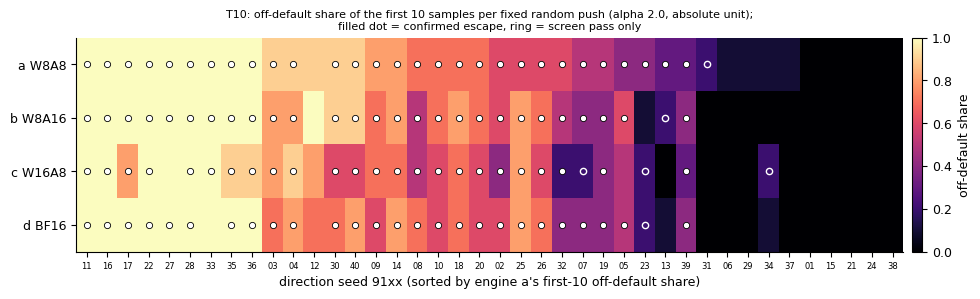

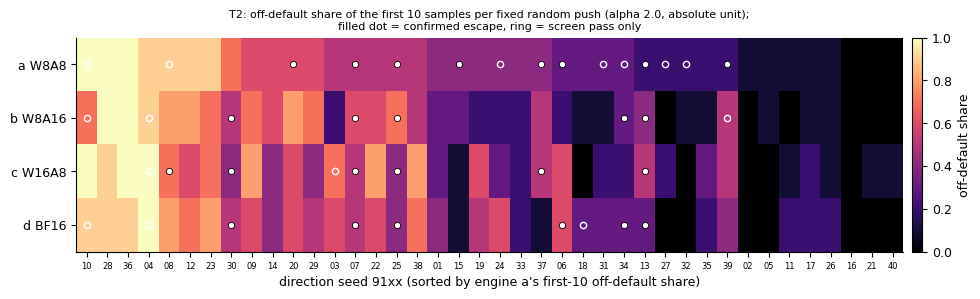

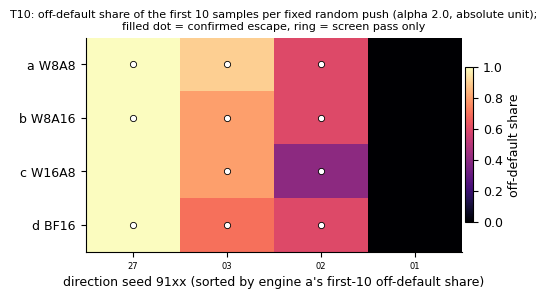

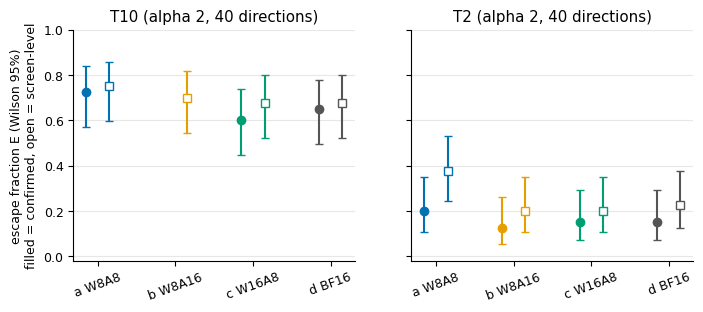

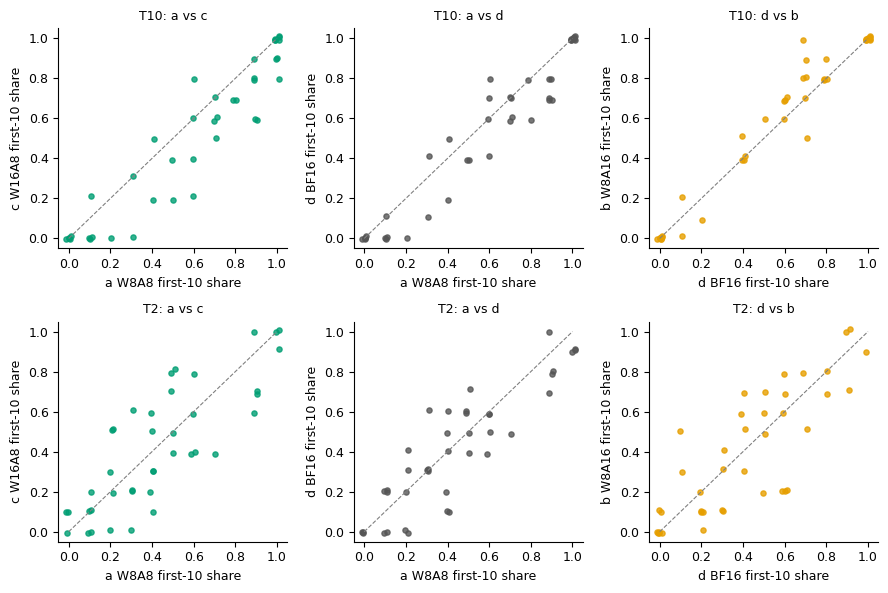

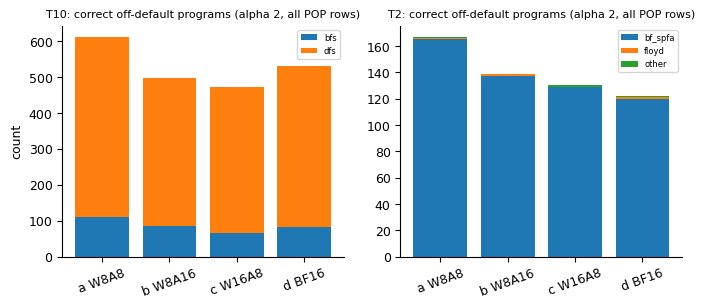

['E_by_engine.png', 'heatmap_directions_T10.png', 'heatmap_directions_T10_demo.png', 'heatmap_directions_T2.png', 'landings.png', 'per_direction_scatter.png']


In [21]:
# As figures6.main(), on the full run's stored results; then the heatmap of the demo directions
FULL_ESC = meta["full_run"]["escape_by_engine"]   # per-direction part of the full run's results/escape_by_engine.json
heatmaps(FULL_ESC)                                 # full run: all 40 directions x 4 engines, T10 and T2
heatmaps(ESC, seeds=DEMO_SEEDS, suffix="_demo")    # demo subset, recomputed in section 5
e_by_engine(FULL_ESC)                              # full run: E per engine, confirmed and screen-level
scatter(FULL_ESC)                                  # full run: per-direction first-10 shares, engine vs engine
landings_fig(meta["full_run"]["landings"])         # full run: where the correct off-default programs land
print(sorted(p.name for p in FIGS.glob("*.png")))

## 10. Results: the raw slots and the escape fraction

**Left panel: the data the whole analysis rests on.** Each column is one CRN slot of a demo direction: first its 10 screen slots (k 0–1), then, after the dotted line, its confirmation slots (k 2–5). Each row is one engine. The colour is the algorithm of that engine's program in that slot; × marks a program that failed the hidden tests, and a blank means the engine did not run the slot. Reading down a column compares the four numerics on identical prompts and sampling uniforms.

**Right panel and table: the demo subset against the full run's stored numbers.**

In these directions the push moves all four engines to the same algorithms (DFS, BFS), mostly in the same slots. Engine c misses direction 9127 only through the pass clause: 3 of its 10 screen programs fail the tests.

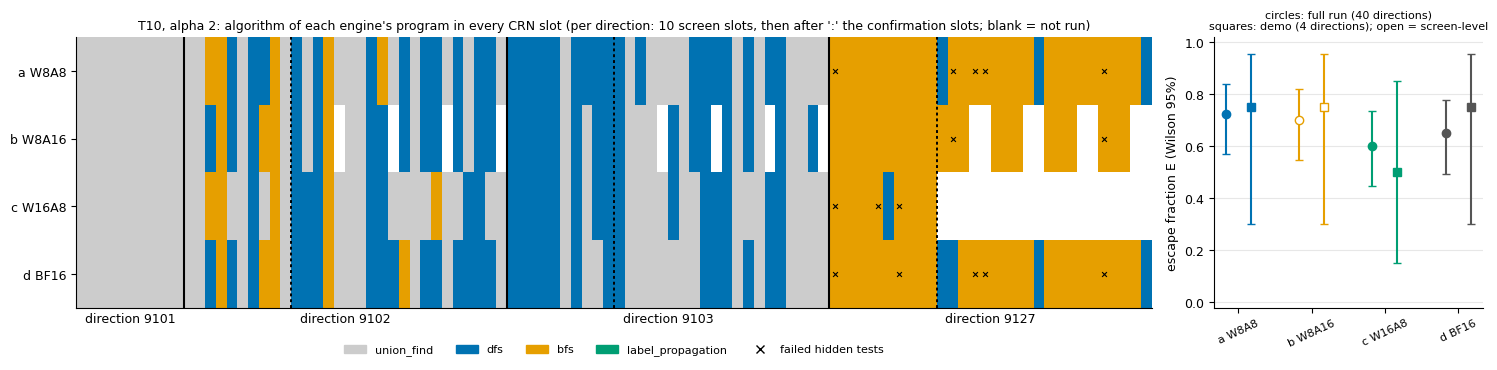

                                                  quantity                      full run (stored)             demo subset (recomputed)
                                                 E(a) W8A8                          0.725 (29/40)                          0.750 (3/4)
                                                E(b) W8A16 incomplete; screen-level 0.700 (28/40) incomplete; screen-level 0.750 (3/4)
                                                E(c) W16A8                          0.600 (24/40)                          0.500 (2/4)
                                                 E(d) BF16                          0.650 (26/40)                          0.750 (3/4)
                                           literal verdict                    NOT_REPRODUCED_HIGH                  NOT_REPRODUCED_HIGH
                                      screen-level verdict                    NOT_REPRODUCED_HIGH                  NOT_REPRODUCED_HIGH
    a-d discordant directions (confirmed), exact McNema

In [22]:
# Left: every CRN slot behind the numbers above. Right: E per engine, demo subset vs full run.
t = TASKS[0]
LABS = ["union_find", "dfs", "bfs", "label_propagation", "other", "invalid", "disputed"]
LCOL = ["#cccccc", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#000000", "#777777"]
slots = sorted({(r["direction_seed"], int(r["sample_id"]), r["template"]) for e in R for r in R[e].get(t, [])})
M = np.full((len(ENGS), len(slots)), np.nan)
fails = []
for i, e in enumerate(ENGS):
    by_slot = {(r["direction_seed"], int(r["sample_id"]), r["template"]): r for r in R.get(e, {}).get(t, [])}
    for j, k in enumerate(slots):
        r = by_slot.get(k)
        if r is None:      # slot not run by this engine (no confirmation after a failed screen)
            continue
        M[i, j] = LABS.index(r["label"]) if r["label"] in LABS else LABS.index("other")
        if not r["passed"]:
            fails.append((j, i))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [4, 1]})
cmap = ListedColormap(LCOL)
cmap.set_bad("white")
ax.imshow(np.ma.masked_invalid(M), aspect="auto", cmap=cmap, vmin=-0.5, vmax=len(LABS) - 0.5, interpolation="nearest")
if fails:
    fx, fy = zip(*fails)
    ax.scatter(fx, fy, marker="x", s=12, color="black", linewidths=0.8)
starts = [j for j, k in enumerate(slots) if j == 0 or k[0] != slots[j - 1][0]]
for j in starts[1:]:
    ax.axvline(j - 0.5, color="black", lw=1.5)
for j in range(1, len(slots)):
    if slots[j][0] == slots[j - 1][0] and slots[j][1] == 2 and slots[j - 1][1] == 1:
        ax.axvline(j - 0.5, color="black", lw=1.4, ls=(0, (1.5, 1.5)))   # screen (k 0-1) | confirmation (k 2-5)
ends = starts[1:] + [len(slots)]
ax.set_xticks([(a + b - 1) / 2 for a, b in zip(starts, ends)], [f"direction {slots[a][0]}" for a in starts])
ax.tick_params(axis="x", length=0)
ax.set_yticks(range(len(ENGS)), [NAME[e] for e in ENGS])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in LCOL[:4]]
handles.append(plt.Line2D([], [], marker="x", color="black", ls=""))
ax.legend(handles, LABS[:4] + ["failed hidden tests"], ncol=5, fontsize=8, loc="upper center",
          bbox_to_anchor=(0.5, -0.1), frameon=False)
ax.set_title(f"{t}, alpha 2: algorithm of each engine's program in every CRN slot "
             "(per direction: 10 screen slots, then after ':' the confirmation slots; blank = not run)", fontsize=9)

FULL = meta["full_run"]["escape_by_engine"]
for i, e in enumerate(ENGS):
    for off, src, mk in ((-0.17, FULL, "o"), (0.17, ESC, "s")):
        v = src[e][t]["alpha"]["2.0"]
        key, wk = ("E_t", "E_wilson") if v["confirmation_complete"] else ("E_screen", "E_screen_wilson")
        y = v[key]
        lo, hi = v[wk]
        ax2.errorbar(i + off, y, yerr=[[y - lo], [hi - y]], fmt=mk, color=COL[e], capsize=3,
                     mfc=COL[e] if key == "E_t" else "white")
ax2.set_xticks(range(len(ENGS)), [NAME[e] for e in ENGS], rotation=25, fontsize=8)
ax2.set_ylim(-0.02, 1.02)
ax2.set_ylabel("escape fraction E (Wilson 95%)")
ax2.set_title(f"circles: full run ({FULL['a'][t]['alpha']['2.0']['n_run']} directions)\n"
              f"squares: demo ({ESC['a'][t]['alpha']['2.0']['n_run']} directions); open = screen-level", fontsize=8)
ax2.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGS / "demo_slots_and_E.png", dpi=150, bbox_inches="tight")
plt.show()


def fmt_E(v):
    if v["confirmation_complete"]:
        return f"{v['E_t']:.3f} ({v['n_confirmed']}/{v['n_run']})"
    return f"incomplete; screen-level {v['E_screen']:.3f} ({v['n_screen_pass']}/{v['n_run']})"


def fmt_p(x):
    return "-" if x is None else f"{x:.2g}"


fv = meta["full_run"]["verdict"][t]
fmc = meta["full_run"]["mcnemar"][f"{t}|a-d|confirmed"]
fsl = meta["full_run"]["slot_flips"][f"{t}|a-d"]
dmc = PAIR.get(f"{t}|a-d|confirmed", {})
dsl = SF[f"{t}|a-d"]
table = [{"quantity": f"E({e}) {ENGINES[e]}", "full run (stored)": fmt_E(FULL[e][t]["alpha"]["2.0"]),
          "demo subset (recomputed)": fmt_E(ESC[e][t]["alpha"]["2.0"])} for e in ENGS]
table += [
    {"quantity": "literal verdict", "full run (stored)": fv["literal_verdict"],
     "demo subset (recomputed)": V[t]["literal_verdict"]},
    {"quantity": "screen-level verdict", "full run (stored)": fv["screen_level_verdict"],
     "demo subset (recomputed)": V[t]["screen_level_verdict"]},
    {"quantity": "a-d discordant directions (confirmed), exact McNemar p",
     "full run (stored)": f"{fmc['n10']}:{fmc['n01']}, p = {fmt_p(fmc['p_two_sided'])}",
     "demo subset (recomputed)": f"{dmc.get('n10')}:{dmc.get('n01')}, p = {fmt_p(dmc.get('p_two_sided'))}"},
    {"quantity": "a-d kappa / Spearman of first-10 shares",
     "full run (stored)": f"{fmc['kappa']:.2f} / {fmc['spearman_share10']:.2f}",
     "demo subset (recomputed)": f"{fmt_p(dmc.get('kappa'))} / {fmt_p(dmc.get('spearman_share10'))}"},
    {"quantity": "CRN screen slots a vs d: off-default rate",
     "full run (stored)": f"{fsl['offdefault_x']:.3f} vs {fsl['offdefault_y']:.3f} ({fsl['n_slots']} slots)",
     "demo subset (recomputed)": f"{dsl['offdefault_x']:.3f} vs {dsl['offdefault_y']:.3f} ({dsl['n_slots']} slots)"},
    {"quantity": "CRN screen slots a vs d: discordant slots, exact McNemar p",
     "full run (stored)": f"{fsl['n10']}:{fsl['n01']}, p = {fmt_p(fsl['p_two_sided'])}",
     "demo subset (recomputed)": f"{dsl['n10']}:{dsl['n01']}, p = {fmt_p(dsl['p_two_sided'])}"},
    {"quantity": "stdlib re-derivation matches the analysis", "full run (stored)": str(meta["full_run"]["rederive_all_match"]),
     "demo subset (recomputed)": str(RD["all_match"])},
    {"quantity": "per-direction outcomes equal to the full run's", "full run (stored)": "-",
     "demo subset (recomputed)": f"{int(check['match'].sum())}/{len(check)}"},
]
print(pd.DataFrame(table).to_string(index=False))